# 03 · Classificação de VEs no eletrodo 7

A [avaliação anterior entre eletrodos](TCC_EIS_Modelos_Basicos/01_modelos_basicos_entre_dispositivos.ipynb) excluiu um dispositivo inteiro por rodada. Aqui, todas as 30 aplicações históricas pertencem ao E7. As três validações mudam a unidade excluída do treino.

| Validação | O que uma rodada deixa de fora | Rodadas |
| --- | --- | ---: |
| LOO | Uma aplicação física | 30 |
| LOBO | Um bloco de aplicações, conforme o agrupamento histórico | 8 |
| LOCO | Uma campanha inteira | 4 |

Cada gota tem três aquisições técnicas e contribui com uma previsão por método de validação. Usamos as sete bandas da diferença de fase em relação ao PBS local, de 0,1 Hz a 1 MHz, fornecidas na tabela histórica do pacote. Essa representação difere das seis bandas de logaritmo do módulo de impedância usadas na análise entre dispositivos. A comparação entre LOO, LOBO e LOCO usa as mesmas gotas e os mesmos atributos.

As quatro campanhas históricas são inicial, T01–T08, ampliada e validação V3. O protocolo de teste final prospectivo será avaliado em outra etapa.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneGroupOut, LeaveOneOut
from sklearn.naive_bayes import GaussianNB

RAIZ = Path.cwd()
PACOTE = RAIZ / 'TCC_EIS_Modelos_Basicos'
assert (PACOTE / 'dados').is_dir(), 'Abra o notebook na pasta raiz do projeto.'
sys.path.insert(0, str(PACOTE))
from modelos_basicos import basic_models, cv_predictions
from sisso_oficial import CLASSES, ROTULO_SISSO, localizar_sisso, prever_sisso

PASTA_FIGURAS = RAIZ / 'imagens_prontas'
PASTA_FIGURAS.mkdir(exist_ok=True)
plt.rcParams.update({
    'font.family': 'Times New Roman', 'pdf.fonttype': 42,
    'figure.dpi': 120, 'font.size': 11, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'legend.fontsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'grid.color': '#D8DEE3', 'grid.alpha': .7, 'axes.edgecolor': '#ABB5BD',
    'figure.constrained_layout.use': True,
})
AZUL, VERDE, TERRACOTA, TEXTO = '#0079B7', '#276445', '#BF5A3C', '#202934'
CAMPANHAS = {'OLD': 'Inicial', 'T': 'T01–T08', 'V2': 'Ampliada', 'V3': 'Validação V3'}
colunas = ['id', 'campanha', 'bloco', 'classe']
atributos = [f'F_b{i}' for i in range(1, 8)]
df = pd.read_csv(PACOTE / 'dados' / 'E7_30_aplicacoes_historicas_caracteristicas.csv',
                 usecols=colunas + atributos)
df['campanha'] = df.campanha.map(CAMPANHAS)
X = df[atributos].to_numpy(float)
y = df.classe.to_numpy()
y_binario = df.classe.eq('HCC1806').to_numpy(dtype=int)
assert X.shape == (30, 7) and np.isfinite(X).all() and df.id.is_unique
assert df.classe.value_counts().to_dict() == {'MCF10A': 15, 'HCC1806': 15}
assert df.bloco.nunique() == 8 and len(df.campanha.unique()) == 4
assert df.groupby('bloco').campanha.nunique().eq(1).all()
display(pd.crosstab(df.campanha, df.classe).reindex(CAMPANHAS.values()))
print('scikit-learn', sklearn.__version__)

classe,HCC1806,MCF10A
campanha,,
Inicial,3,3
T01–T08,4,4
Ampliada,6,6
Validação V3,2,2


scikit-learn 1.9.1


## Avaliação dos modelos

Comparamos regressão logística, KNN, Random Forest, Gaussian Naive Bayes, LDA e SISSO oficial 3.0.2 com SVM linear. Cada divisão refaz o treinamento, inclusive transformações e escolha de descritores. O SISSO seleciona dois descritores com busca L0 e o SVM linear usa C=1. As configurações são fixas nos três esquemas.

A primeira figura mostra a acurácia total sobre as 30 aplicações. A segunda mostra os acertos em cada bloco ou campanha deixados inteiramente de fora. Em cada célula do mapa, o denominador é o número de aplicações daquele grupo. [Código-fonte do SISSO 3.0.2](https://github.com/rouyang2017/SISSO/tree/50159de1c9388dd4e5b0bae2421df402bcad8edb).

In [2]:
validacoes = {
    'LOO': (LeaveOneOut(), None),
    'LOBO': (LeaveOneGroupOut(), df.bloco.to_numpy()),
    'LOCO': (LeaveOneGroupOut(), df.campanha.to_numpy()),
}
modelos_basicos = basic_models()
modelos = {nome: modelos_basicos[nome] for nome in ('Regressão logística', 'KNN (k=5)', 'Random Forest')}
modelos['Gaussian Naive Bayes'] = GaussianNB()
modelos['LDA'] = LinearDiscriminantAnalysis()
nomes = [*modelos, ROTULO_SISSO]
exe = localizar_sisso(RAIZ)
previsoes = {}
descritores = []
for validacao, (divisor, grupos) in validacoes.items():
    for nome, modelo in modelos.items():
        p = cv_predictions(X, y_binario, divisor, groups=grupos, model=modelo)
        previsoes[validacao, nome] = np.asarray(CLASSES)[p]

    sisso = np.empty(len(y), dtype=object)
    contagem_teste = np.zeros(len(y), dtype=int)
    for treino, teste in divisor.split(X, y, grupos):
        if grupos is not None:
            assert set(grupos[treino]).isdisjoint(grupos[teste])
        assert set(y[treino]) == set(CLASSES)
        sisso[teste], expressoes = prever_sisso(X[treino], y[treino], X[teste], exe)
        contagem_teste[teste] += 1
        excluido = df.id.iloc[teste[0]] if grupos is None else grupos[teste[0]]
        descritores.append((validacao, excluido, *expressoes))
    assert (contagem_teste == 1).all()
    previsoes[validacao, ROTULO_SISSO] = sisso

linhas = []
for (validacao, nome), pred in previsoes.items():
    acertos = np.count_nonzero(pred == y)
    linhas.append((validacao, nome, acertos, len(y), acertos / len(y)))
resultado = pd.DataFrame(linhas, columns=['Validação', 'Modelo', 'Acertos', 'Total', 'Acurácia'])
resumo = resultado.assign(Resumo=[
    f'{a}/{n} ({100 * p:.1f}%)'.replace('.', ',')
    for a, n, p in zip(resultado.Acertos, resultado.Total, resultado.Acurácia)
]).pivot(index='Modelo', columns='Validação', values='Resumo').loc[nomes, list(validacoes)]
display(resumo)
descritores_sisso = pd.DataFrame(descritores, columns=['Validação', 'Grupo excluído', 'Descritor 1', 'Descritor 2'])
assert descritores_sisso['Validação'].value_counts().to_dict() == {'LOO': 30, 'LOBO': 8, 'LOCO': 4}
display(descritores_sisso.query("Validação == 'LOCO'"))

Validação,LOO,LOBO,LOCO
Modelo,,,
Regressão logística,"13/30 (43,3%)","17/30 (56,7%)","11/30 (36,7%)"
KNN (k=5),"18/30 (60,0%)","22/30 (73,3%)","19/30 (63,3%)"
Random Forest,"13/30 (43,3%)","18/30 (60,0%)","14/30 (46,7%)"
Gaussian Naive Bayes,"17/30 (56,7%)","16/30 (53,3%)","13/30 (43,3%)"
LDA,"14/30 (46,7%)","16/30 (53,3%)","15/30 (50,0%)"
SISSO 3.0.2 + SVM linear,"15/30 (50,0%)","14/30 (46,7%)","15/30 (50,0%)"


,Validação,Grupo excluído,Descritor 1,Descritor 2
38,LOCO,Ampliada,(z2*z7),(z2+z4)
39,LOCO,Inicial,(z1*z7),(z5-z6)
40,LOCO,T01–T08,(z1*z4),(z3+z4)
41,LOCO,Validação V3,(z1*z7),(z4-z7)


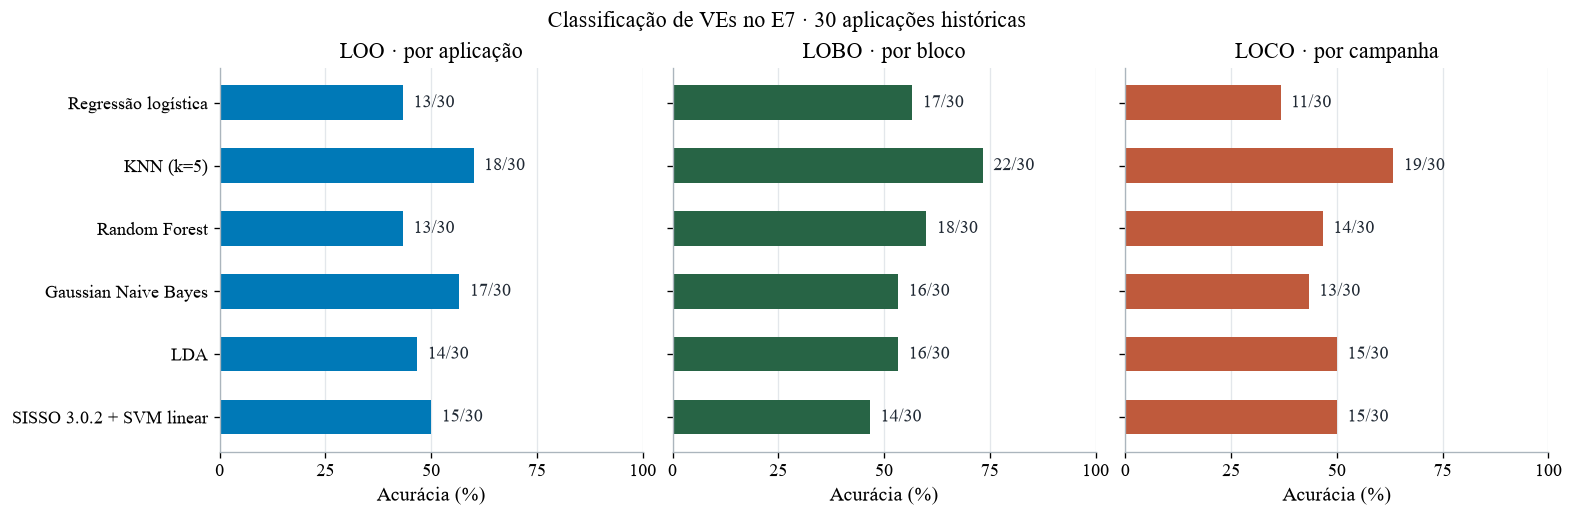

In [3]:
titulos = ['LOO · por aplicação', 'LOBO · por bloco', 'LOCO · por campanha']
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
posicoes = np.arange(len(nomes))
for ax, validacao, titulo, cor in zip(axs, validacoes, titulos, [AZUL, VERDE, TERRACOTA]):
    dados = resultado[resultado['Validação'].eq(validacao)].set_index('Modelo').loc[nomes]
    ax.barh(posicoes, dados.Acurácia, color=cor, height=.55)
    for pos, r in enumerate(dados.itertuples()):
        legenda = f'{r.Acertos}/{r.Total}'
        if r.Acurácia > .85:
            ax.text(r.Acurácia - .025, pos, legenda, va='center', ha='right', color='white')
        else:
            ax.text(r.Acurácia + .025, pos, legenda, va='center', color=TEXTO)
    ax.set(xticks=np.linspace(0, 1, 5), xlim=(0, 1), title=titulo, xlabel='Acurácia (%)')
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, symbol='', decimals=0))
    ax.set_yticks(posicoes, nomes)
    ax.grid(axis='x')
axs[0].invert_yaxis()
fig.suptitle('Classificação de VEs no E7 · 30 aplicações históricas', fontsize=13)
fig.savefig(PASTA_FIGURAS / 'modelos_e7_loo_lobo_loco.pdf', bbox_inches='tight')
plt.show()

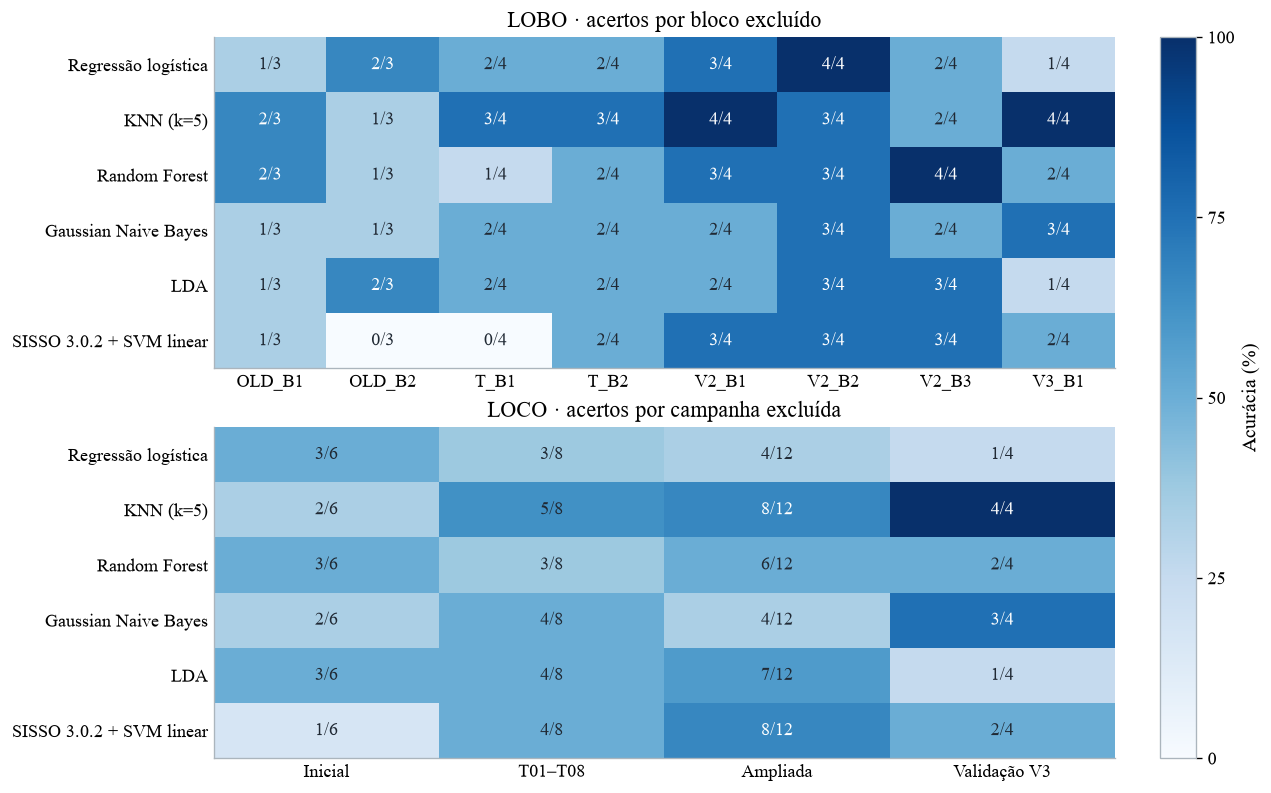

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(10.5, 6.5), sharey=True)
for ax, validacao, coluna, ordem, titulo in [
    (axs[0], 'LOBO', 'bloco', df.bloco.unique(), 'LOBO · acertos por bloco excluído'),
    (axs[1], 'LOCO', 'campanha', list(CAMPANHAS.values()), 'LOCO · acertos por campanha excluída'),
]:
    grupos = df[coluna].to_numpy()
    totais = np.array([np.count_nonzero(grupos == grupo) for grupo in ordem])
    acertos = np.array([
        [np.count_nonzero((grupos == grupo) & (previsoes[validacao, nome] == y))
         for grupo in ordem] for nome in nomes
    ])
    esperados = resultado[resultado['Validação'].eq(validacao)].set_index('Modelo').loc[nomes, 'Acertos']
    assert (acertos.sum(axis=1) == esperados.to_numpy()).all()
    proporcao = acertos / totais
    cores = ax.imshow(proporcao, cmap='Blues', vmin=0, vmax=1, aspect='auto',
                      interpolation='nearest')
    for (i, j), valor in np.ndenumerate(acertos):
        ax.text(j, i, f'{valor}/{totais[j]}', ha='center', va='center',
                color='white' if proporcao[i, j] >= .65 else TEXTO)
    ax.set_xticks(range(len(ordem)), ordem)
    ax.set_yticks(np.arange(len(nomes)), nomes)
    ax.tick_params(length=0)
    ax.set_title(titulo)
escala = fig.colorbar(cores, ax=axs, ticks=np.linspace(0, 1, 5),
                      label='Acurácia (%)', fraction=.05)
escala.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, symbol='', decimals=0))
fig.savefig(PASTA_FIGURAS / 'modelos_e7_acertos_por_grupo.pdf', bbox_inches='tight')
plt.show()

## Leitura para a discussão

LOO avalia uma nova gota com outras aplicações da mesma campanha ainda disponíveis para treino. LOBO avalia um novo bloco. LOCO avalia uma campanha histórica inteira fora do treino. Os três resultados descrevem cenários distintos no E7. Diferenças de poucos acertos entre métodos devem ser interpretadas considerando as 30 aplicações e a reutilização dessas mesmas aplicações nas três validações.

O KNN teve os maiores totais entre os modelos comparados: 18/30 em LOO, 22/30 em LOBO e 19/30 em LOCO. Em LOCO, acertou 2/6 na campanha inicial e 4/4 na validação V3. O SISSO oficial com SVM linear ficou entre 14 e 15 acertos nas três validações.

O Gaussian Naive Bayes acertou 17/30 em LOO, 16/30 em LOBO e 13/30 em LOCO.

Com as sete bandas de fase, a LDA acertou 14/30 em LOO, 16/30 em LOBO e 15/30 em LOCO.